The NEW R-squared score is: 0.82


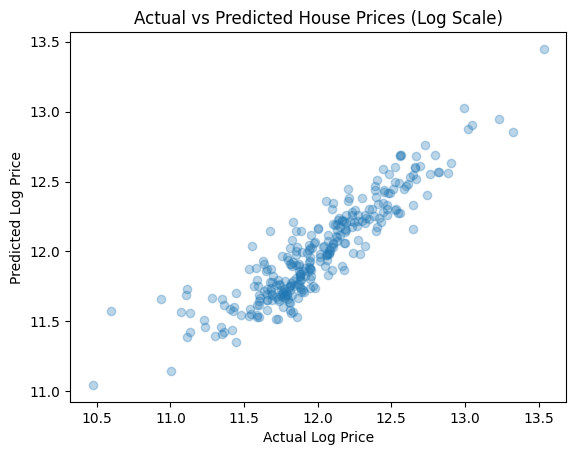


--- Try it yourself! ---
Enter square footage (e.g., 2000): 3399
Enter number of bedrooms (e.g., 3): 2
Enter number of bathrooms (e.g., 2): 2
Enter overall quality (1-10, e.g., 7): 8
Enter basement sqft (e.g., 1000): 3399
Estimated House Price: $480,829.62


In [11]:
# Block 1: Importing the Libraries
import pandas as pd
import numpy as np # NEW: We need numpy for the math log function
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score
import matplotlib.pyplot as plt

# Block 2: Loading and Preparing the Data
df = pd.read_csv('train.csv')

# NEW: We added 2 more powerful features from the dataset
X = df[['GrLivArea', 'BedroomAbvGr', 'FullBath', 'OverallQual', 'TotalBsmtSF']]

# NEW: We use np.log1p to flatten the price curve so the model learns better
y = np.log1p(df['SalePrice'])

# Block 3: Splitting the Data
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Block 4: Creating and Training the Model
model = LinearRegression()
model.fit(X_train, y_train)

# Block 5: Testing and Evaluating the Model
y_pred = model.predict(X_test)

# NEW: We have to compare the log of the predictions to the log of the real prices
r2 = r2_score(y_test, y_pred)
print(f"The NEW R-squared score is: {r2:.2f}")

# Block 6: Visualizing the Results
plt.scatter(y_test, y_pred, alpha=0.3)
plt.xlabel("Actual Log Price")
plt.ylabel("Predicted Log Price")
plt.title("Actual vs Predicted House Prices (Log Scale)")
plt.show()

# Block 7: Making a Custom Prediction
print("\n--- Try it yourself! ---")
sqft = float(input("Enter square footage (e.g., 2000): "))
beds = int(input("Enter number of bedrooms (e.g., 3): "))
baths = int(input("Enter number of bathrooms (e.g., 2): "))
qual = int(input("Enter overall quality (1-10, e.g., 7): "))
bsmt = float(input("Enter basement sqft (e.g., 1000): "))

# NEW: Added the new inputs to the DataFrame
custom_input = pd.DataFrame({
    'GrLivArea': [sqft],
    'BedroomAbvGr': [beds],
    'FullBath': [baths],
    'OverallQual': [qual],
    'TotalBsmtSF': [bsmt]
})

# Predict the log price
predicted_log_price = model.predict(custom_input)

# NEW: We must convert the log price back to a real dollar amount using np.expm1
predicted_price = np.expm1(predicted_log_price)

print(f"Estimated House Price: ${predicted_price[0]:,.2f}")